# Example: run the iRPF pipeline on your EEG data

This notebook is a starting point for testing the pipeline with your own recording and editing the potato configuration.

> **Required project file:** `full_irpf_python_only.py` must be in the project folder. It provides `FullIRPF`, `PotatoConfig`, and `save_result_outputs`.

Keep `run_irpf.py`, `irpf_utils.py`, `potato_config.py`, `diagnostic_plot.py`, and `full_irpf_python_only.py` together.


## 1. Install dependencies

If the project files are in the current notebook folder, run:

In [6]:
%pip install -r /content/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 89.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [ipympl]


If installation changes an already-imported package, restart the notebook runtime. In Colab, upload or clone the project files and your EEG and sensor files into the runtime.

In [8]:
%matplotlib inline

## 2. Set input files and sampling parameters

Update these paths and values for your recording. The EEG text file should have one sample per row and one channel per column. The sensor file lists channel names in that same column order.

In [9]:
from pathlib import Path

SENSOR_FILE = Path('/content/8 canali.txt') # TO BE CHANGED
EEG_FILE = Path('/content/recording1.txt') # TO BE CHANGED
OUTPUT_DIR = Path('/content/irpf_output')

SR = 512          # sampling rate in Hz
WL = SR           # epoch length in samples; here, 1 second
SLIDE = 0         # 0 means non-overlapping epochs


## 3. Inspect and customize potato configurations

Edit `IRPF_CONFIG` in `potato_config.py` to change channel groups, bands, and metrics. This cell lists the configured potatoes compatible with the sensor names in your recording.

In [11]:
from potato_config import IRPF_CONFIG # CONGIF SHOULD BE ADAPTED TO DATA
from run_irpf import _read_sensor_names

sensors = _read_sensor_names(SENSOR_FILE)
available = set(sensors)
usable_potatoes = [
    cfg for cfg in IRPF_CONFIG
    if cfg['channels'] is None or all(ch.upper() in available for ch in cfg['channels'])
]
print('Sensors:', sensors)
print(f'Usable potatoes: {len(usable_potatoes)} / {len(IRPF_CONFIG)}')
for cfg in usable_potatoes:
    print(f"{cfg['name']}: {cfg['channels'] or 'ALL'} | {cfg['low_freq']}-{cfg['high_freq']} Hz | {cfg['metric']}")


Sensors: ['O1', 'C5', 'FP1', 'CZ', 'FZ', 'FP2', 'C6', 'O2']
Usable potatoes: 12 / 12
p1_ocular_cov_riemann: ['FP1', 'FP2', 'FZ'] | 0.5-10.0 Hz | riemann
p2_ocular_amp_euclid: ['FP1', 'FP2', 'FZ'] | 0.5-10.0 Hz | euclid
p3_frontal_local_cov: ['FP1', 'FP2', 'FZ'] | 1.0-20.0 Hz | riemann
p4_central_local_cov: ['C5', 'CZ', 'C6'] | 1.0-20.0 Hz | riemann
p5_occipital_local_cov: ['O1', 'O2'] | 1.0-20.0 Hz | riemann
p6_frontal_single_lowmid: ['FP1', 'FP2', 'FZ'] | 0.5-20.0 Hz | euclid
p7_central_single_lowmid: ['C5', 'CZ', 'C6'] | 0.5-20.0 Hz | euclid
p8_occipital_single_lowmid: ['O1', 'O2'] | 0.5-20.0 Hz | euclid
p9_frontal_muscle_highfreq: ['FP1', 'FP2', 'FZ'] | 20.0-44.0 Hz | euclid
p10_posterior_muscle_highfreq: ['C5', 'CZ', 'C6', 'O1', 'O2'] | 20.0-44.0 Hz | euclid
p11_global_cov_riemann: ['FP1', 'FZ', 'FP2', 'C5', 'CZ', 'C6', 'O1', 'O2'] | 0.5-20.0 Hz | riemann
p12_global_amp_euclid: ['FP1', 'FZ', 'FP2', 'C5', 'CZ', 'C6', 'O1', 'O2'] | 0.5-20.0 Hz | euclid


## 4. Choose epoch selection and run

Choose a selection mode. `from_ordered_epoch` uses a 1-based index in the order from lower to higher SQI.

Sensor file: /content/8 canali.txt
EEG file: /content/recording1.txt
Sensors: ['O1', 'C5', 'FP1', 'CZ', 'FZ', 'FP2', 'C6', 'O2']
EEG shape: (82848, 8)
Duration [s]: 161.8125
Potatoes used: ['p1_ocular_cov_riemann', 'p2_ocular_amp_euclid', 'p3_frontal_local_cov', 'p4_central_local_cov', 'p5_occipital_local_cov', 'p6_frontal_single_lowmid', 'p7_central_single_lowmid', 'p8_occipital_single_lowmid', 'p9_frontal_muscle_highfreq', 'p10_posterior_muscle_highfreq', 'p11_global_cov_riemann', 'p12_global_amp_euclid']
potato leads=['FP1', 'FP2', 'FZ'] bp=(0.5, 10.0) kind=riemann step=1 pth=0.0515859 kept=147/154
potato leads=['FP1', 'FP2', 'FZ'] bp=(0.5, 10.0) kind=riemann step=2 pth=0.0627878 kept=141/147
potato leads=['FP1', 'FP2', 'FZ'] bp=(0.5, 10.0) kind=riemann step=3 pth=0.0862385 kept=130/141
potato leads=['FP1', 'FP2', 'FZ'] bp=(0.5, 10.0) kind=riemann step=4 pth=0.0837821 kept=123/130
potato leads=['FP1', 'FP2', 'FZ'] bp=(0.5, 10.0) kind=euclid step=1 pth=0.0221984 kept=149/154
potato l

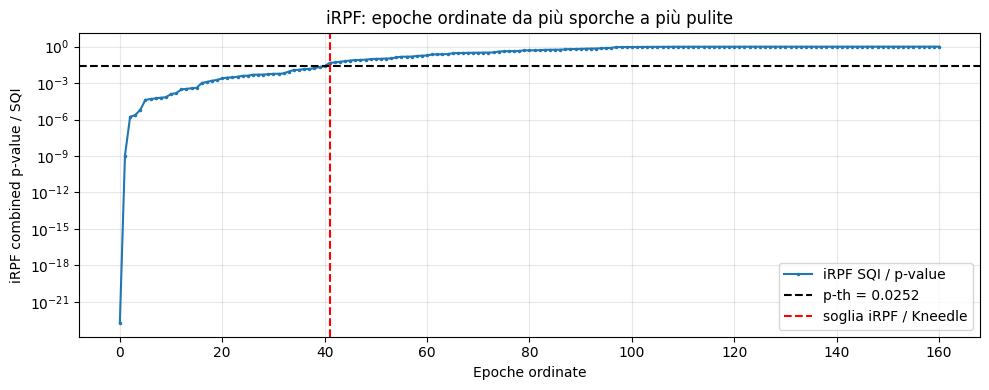

Epoche totali: 161
Epoche selezionate: 157
Modalità salvataggio: from_ordered_epoch
Soglia epoca: 41
File EEG pulito: /content/irpf_output/recording1_clean_from_ordered_epoch_5_n_157.txt
Risultati numerici: /content/irpf_output/recording1_full_irpf_results


In [12]:
from run_irpf import run_pipeline

run = run_pipeline(
    sensor_file=SENSOR_FILE,
    eeg_file=EEG_FILE,
    output_dir=OUTPUT_DIR,
    sr=SR,
    wl=WL,
    slide=SLIDE,
    epoch_save_mode='from_ordered_epoch',  # also: after_threshold, best_n, all
    save_from_ordered_epoch=5,
    n_best_epochs=136,
    show_plot=True,
)


In [13]:
print('Threshold epoch:', run['threshold_epoch'])
print('Selected epochs:', len(run['selected_epochs']))
print('Cleaned signal:', run['output_file'])
print('Numeric results:', run['results_dir'])


Threshold epoch: 41
Selected epochs: 157
Cleaned signal: /content/irpf_output/recording1_clean_from_ordered_epoch_5_n_157.txt
Numeric results: /content/irpf_output/recording1_full_irpf_results


## 5. Explore the interactive diagnostic plot

This plot has a time-window slider, amplitude scale control, potato activation heatmap, and original-epoch mapping. If `%matplotlib widget` is unsupported, use `%matplotlib inline` for static plots or follow your environment's instructions for enabling ipympl.

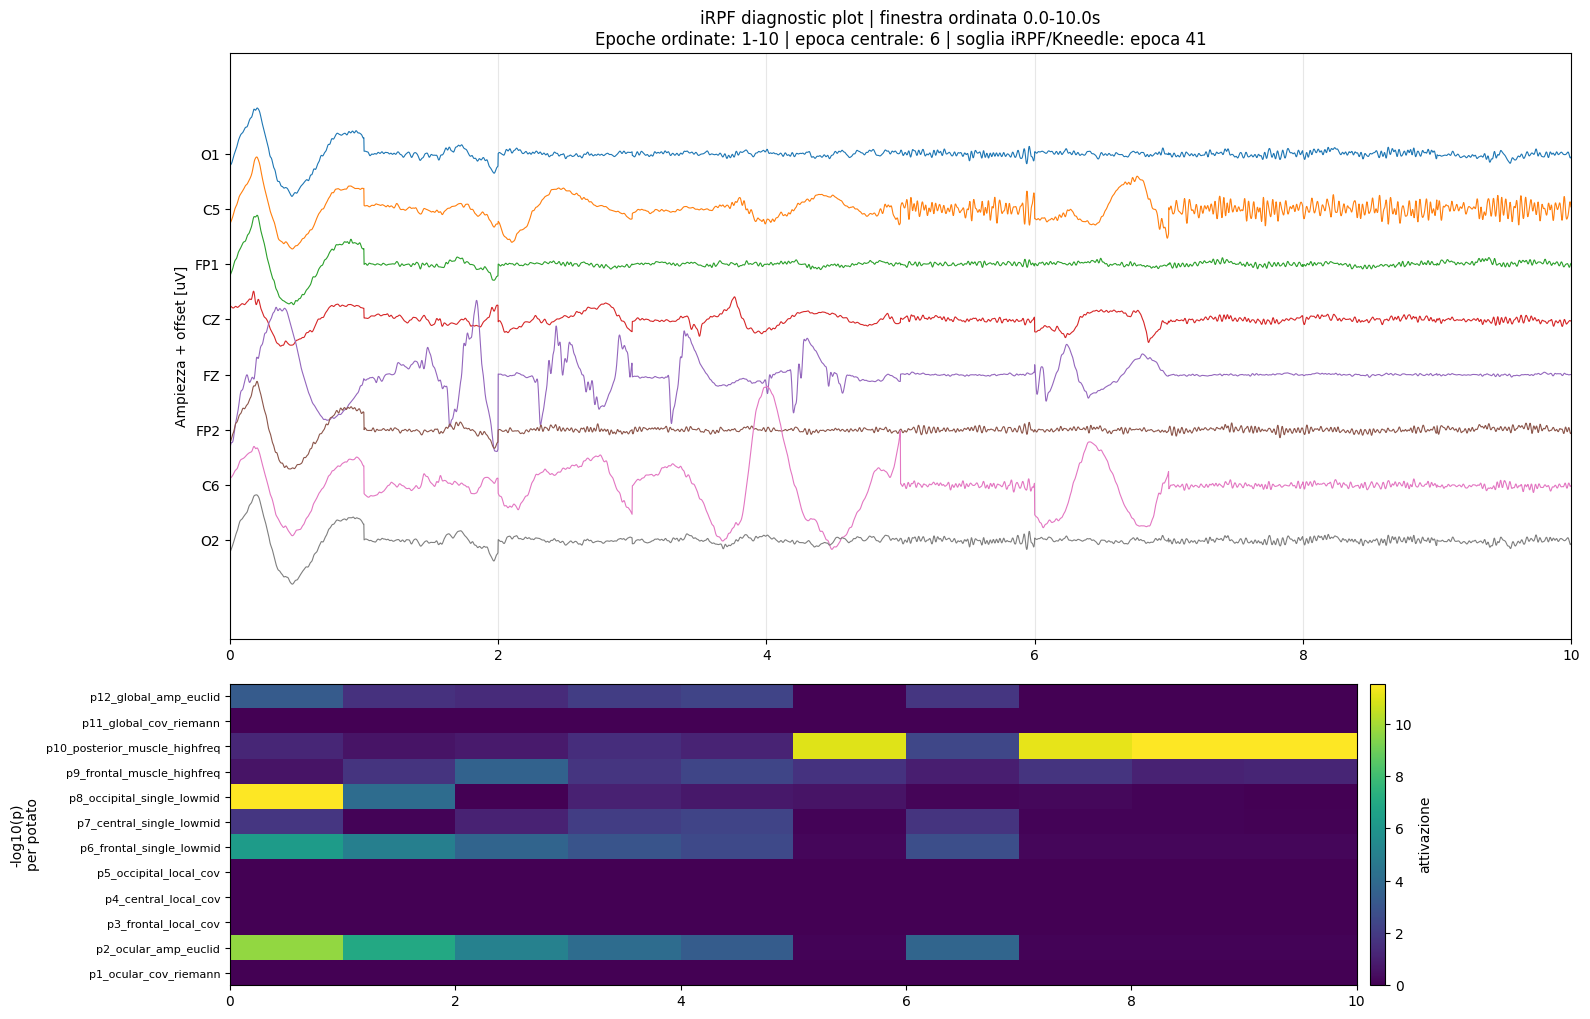

IntSlider(value=0, continuous_update=False, description='Start', layout=Layout(width='750px'), max=77312, step…

FloatSlider(value=1.0, continuous_update=False, description='Scala', layout=Layout(width='750px'), max=5.0, mi…

HTML(value="<b>Finestra ordinata:</b> 0.0-10.0 s&nbsp;&nbsp; | &nbsp;&nbsp;<b>Epoche ordinate:</b> 1-10&nbsp;&…

{'figure': <Figure size 1600x1000 with 3 Axes>,
 'axes': (<Axes: title={'center': 'iRPF diagnostic plot | finestra ordinata 0.0-10.0s\nEpoche ordinate: 1-10 | epoca centrale: 6 | soglia iRPF/Kneedle: epoca 41'}, ylabel='Ampiezza + offset [uV]'>,
  <Axes: ylabel='-log10(p)\nper potato'>),
 'previous_button': Button(description='Precedente', layout=Layout(width='140px'), style=ButtonStyle()),
 'next_button': Button(description='Successiva', layout=Layout(width='140px'), style=ButtonStyle()),
 'start_slider': IntSlider(value=0, continuous_update=False, description='Start', layout=Layout(width='750px'), max=77312, step=512),
 'scale_slider': FloatSlider(value=1.0, continuous_update=False, description='Scala', layout=Layout(width='750px'), max=5.0, min=0.3),
 'diagnostic_label': HTML(value="<b>Finestra ordinata:</b> 0.0-10.0 s&nbsp;&nbsp; | &nbsp;&nbsp;<b>Epoche ordinate:</b> 1-10&nbsp;&nbsp; | &nbsp;&nbsp;<b>Epoca centrale:</b> 6&nbsp;&nbsp; | &nbsp;&nbsp;<b>Soglia iRPF:</b> epoca 41, temp

In [15]:
from diagnostic_plot import plot_diagnostics

plot_diagnostics(
    result=run['result'],
    sorted_epochs=run['epochs_sorted'],
    sensors=run['sensors'],
    sr=SR,
    threshold_epoch=run['threshold_epoch'],
    potato_config=usable_potatoes,
)


## Notes

- Check that sensor labels match the EEG column order.
- Confirm the sampling rate and epoch length before interpreting results.
- The runner concatenates selected epochs into a continuous text signal; epoch boundaries are not marked in that file.
- Review the selected range and diagnostic plot before using the cleaned signal downstream.
